# Klasifikasi Gender (Pria/Wanita) — GoogLeNet (Transfer Learning)
Dataset: `ashishjangra27/gender-recognition-200k-images-celeba`  
Framework: PyTorch | Arsitektur pada kode saat ini: **AlexNet** | Bobot awal ImageNet, full fine-tuning.

Eksperimen menggunakan 20.000 gambar train, 5.000 validation, dan 5.000 test dari split resmi, dengan seed 42.

**Sebelum training:** pilih Runtime → Change runtime type → T4 GPU. Output yang sudah tersimpan dapat dibaca tanpa menjalankan ulang training.

**Catatan pemeriksaan:** nama file menargetkan GoogLeNet, tetapi kode saat ini memakai `MODEL_NAME = "alexnet"`. Output penyimpanan yang ada mencatat AlexNet. Karena itu, output tersebut adalah hasil AlexNet, belum hasil GoogLeNet. Untuk eksperimen GoogLeNet, ubah `MODEL_NAME` menjadi `"googlenet"` dan jalankan training baru secara manual. Penyuntingan penjelasan ini tidak mengubah kode atau output lama.


## 1. Download Dataset dari Kaggle

Cell berikut meminta file autentikasi Kaggle, mengunduh dataset, dan mengekstraknya ke `/content/dataset`. Dataset lengkap diunduh terlebih dahulu; subset yang dipakai untuk eksperimen dipilih pada bagian Dataset & DataLoader. Bagian ini diperlukan untuk training/evaluasi pada runtime baru, tetapi tidak diperlukan untuk prediksi satu gambar dari model yang sudah disimpan.


In [1]:
# Upload kaggle.json (Kaggle -> Settings -> API -> Create New Token)
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"tinoinformatika","key":"[REDACTED_KAGGLE_TOKEN]"}'}

In [2]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/kaggle.json
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d ashishjangra27/gender-recognition-200k-images-celeba -p /content
!unzip -q /content/gender-recognition-200k-images-celeba.zip -d /content/dataset

Dataset URL: https://www.kaggle.com/datasets/ashishjangra27/gender-recognition-200k-images-celeba
License(s): CC-BY-NC-SA-4.0
100% 1.32G/1.32G [00:13<00:00, 103MB/s]



## 2. Konfigurasi Eksperimen

Kelima arsitektur harus memakai dataset, seed, hyperparameter, preprocessing, dan environment yang sama. Nilai `MODEL_NAME` pada file ini saat diperiksa adalah `"alexnet"`.

Konfigurasi saat ini: seed 42, 8 epoch, batch size 64, learning rate `1e-4`, gambar RGB 224 × 224, dua kelas, dan `num_workers=2`. Optimizer Adam dan mixed precision disiapkan pada bagian model. Ukuran subset: train 20.000, validation 5.000, test 5.000.


In [3]:
import os, time, random, io
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
from tqdm.auto import tqdm
from PIL import Image

# ===== Hyperparameter (identik untuk semua model) =====
MODEL_NAME  = "googlenet"   # alexnet | vgg16 | vgg19 | googlenet | resnet18
SEED        = 42
EPOCHS      = 8
BATCH_SIZE  = 64
LR          = 1e-4
IMG_SIZE    = 224
NUM_CLASSES = 2
NUM_WORKERS = 2

# ===== Ukuran subset (ubah ke None untuk memakai data penuh) =====
N_TRAIN, N_VAL, N_TEST = 20000, 5000, 5000

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU (lambat!)")

Device: cuda | Tesla T4


## 3. Dataset & DataLoader

Folder Train, Validation, dan Test dicari dari hasil ekstraksi. `ImageFolder` menetapkan mapping Female=0 dan Male=1. Subset diambil tanpa penggantian menggunakan seed 42 pada masing-masing split.

Gambar train diberi resize, horizontal flip, rotasi, dan color jitter, lalu dinormalisasi memakai statistik ImageNet. Validation dan test hanya memakai resize serta normalisasi. DataLoader train diacak; validation/test tidak diacak. Preview menampilkan contoh gambar validation.


In [4]:
# Cari folder Train / Validation / Test secara otomatis
def find_dir(root, name):
    for dp, dn, _ in os.walk(root):
        for d in dn:
            if d.lower() == name.lower():
                return os.path.join(dp, d)
    raise FileNotFoundError(f"Folder '{name}' tidak ditemukan di {root}")

ROOT = "/content/dataset"
train_dir = find_dir(ROOT, "Train")
val_dir   = find_dir(ROOT, "Validation")
test_dir  = find_dir(ROOT, "Test")
print(train_dir, val_dir, test_dir, sep="\n")

mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # statistik ImageNet

train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

train_full = datasets.ImageFolder(train_dir, transform=train_tf)
val_full   = datasets.ImageFolder(val_dir,   transform=eval_tf)
test_full  = datasets.ImageFolder(test_dir,  transform=eval_tf)
class_names = train_full.classes
print("Kelas:", train_full.class_to_idx)

def make_subset(ds, n, seed):
    if n is None or n >= len(ds):
        return ds
    g = np.random.RandomState(seed)
    idx = g.choice(len(ds), n, replace=False)
    return Subset(ds, idx.tolist())

train_ds = make_subset(train_full, N_TRAIN, SEED)
val_ds   = make_subset(val_full,   N_VAL,   SEED)
test_ds  = make_subset(test_full,  N_TEST,  SEED)
print(f"Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}")

g = torch.Generator(); g.manual_seed(SEED)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS, pin_memory=True, generator=g)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

/content/dataset/Dataset/Train
/content/dataset/Dataset/Validation
/content/dataset/Dataset/Test
Kelas: {'Female': 0, 'Male': 1}
Train: 20000 | Val: 5000 | Test: 5000


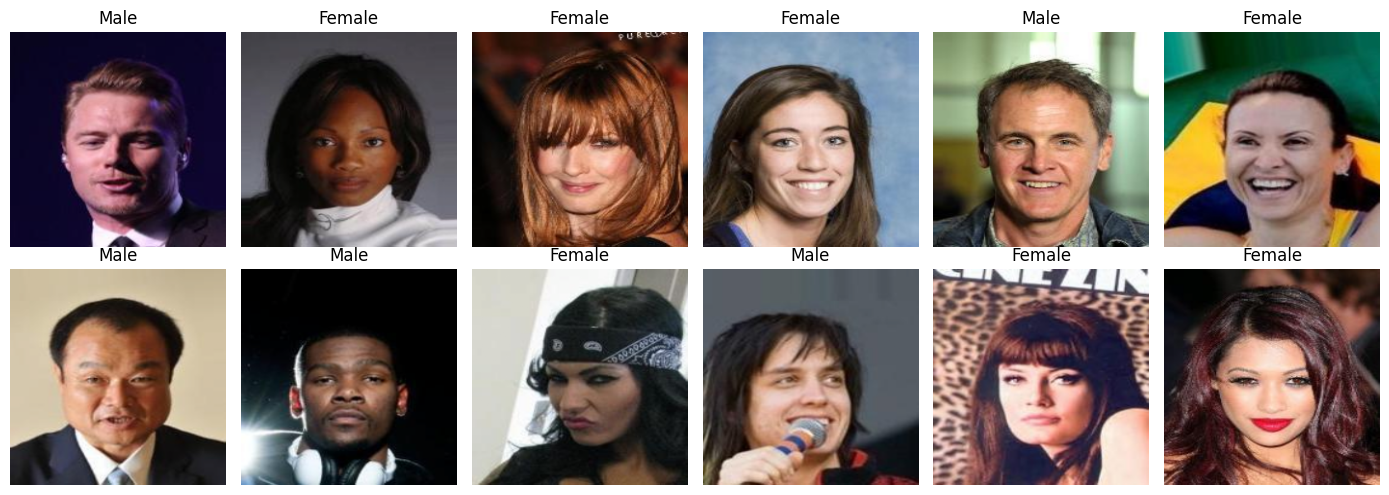

In [5]:
# Tampilkan beberapa contoh gambar
imgs, labels = next(iter(val_loader))
inv = transforms.Normalize([-m/s for m, s in zip(mean, std)], [1/s for s in std])
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax, im, lb in zip(axes.flat, imgs, labels):
    ax.imshow(inv(im).clamp(0, 1).permute(1, 2, 0).numpy())
    ax.set_title(class_names[lb]); ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Model: AlexNet Pre-trained

AlexNet memakai lima layer konvolusi dan tiga layer fully connected. Layer classifier terakhir diganti agar menghasilkan dua kelas: Female dan Male. Bobot awal berasal dari ImageNet dan seluruh parameter dilatih kembali (full fine-tuning). Jumlah parameter dihitung dari model yang dibangun. Loss memakai CrossEntropyLoss; optimizer memakai Adam dengan learning rate yang ditentukan; GradScaler mendukung mixed precision pada GPU.

**Target file: GoogLeNet.** Periksa catatan status pada awal notebook: kode/output yang tersimpan belum konsisten dengan target tersebut. Judul file saja tidak mengubah arsitektur yang dijalankan.


In [6]:
def build_model(name, num_classes=2):
    if name == "alexnet":
        m = models.alexnet(weights=models.AlexNet_Weights.IMAGENET1K_V1)
        m.classifier[6] = nn.Linear(m.classifier[6].in_features, num_classes)
    elif name == "vgg16":
        m = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)
        m.classifier[6] = nn.Linear(m.classifier[6].in_features, num_classes)
    elif name == "vgg19":
        m = models.vgg19(weights=models.VGG19_Weights.IMAGENET1K_V1)
        m.classifier[6] = nn.Linear(m.classifier[6].in_features, num_classes)
    elif name == "googlenet":
        m = models.googlenet(weights=models.GoogLeNet_Weights.IMAGENET1K_V1, aux_logits=True)
        m.aux_logits = False; m.aux1 = None; m.aux2 = None   # nonaktifkan auxiliary classifier
        m.fc = nn.Linear(m.fc.in_features, num_classes)
    elif name == "resnet18":
        m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        m.fc = nn.Linear(m.fc.in_features, num_classes)
    else:
        raise ValueError(name)
    return m

model = build_model(MODEL_NAME, NUM_CLASSES).to(device)
total = sum(p.numel() for p in model.parameters())
print(f"{MODEL_NAME} | total parameter: {total/1e6:.1f} M")

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))   # mixed precision (sama di semua model)

Downloading: "https://download.pytorch.org/models/googlenet-1378be20.pth" to /root/.cache/torch/hub/checkpoints/googlenet-1378be20.pth


100%|██████████| 49.7M/49.7M [00:00<00:00, 162MB/s]
/usr/local/lib/python3.13/dist-packages/torchvision/models/googlenet.py:341: UserWarning: auxiliary heads in the pretrained googlenet model are NOT pretrained, so make sure to train them
  warnings.warn(


googlenet | total parameter: 5.6 M


## 5. Training Loop

Pada setiap epoch, model belajar dari train set, lalu dievaluasi pada validation set. Loss dan accuracy kedua split dicatat dalam history. Bobot dengan validation accuracy tertinggi disimpan sebagai `*_gender_best.pth`; test set tidak dipakai untuk memilih checkpoint.

Training dijalankan selama 8 epoch. File checkpoint pada `/content` berada di penyimpanan sementara runtime. Jangan menjalankan ulang bagian ini hanya untuk mencoba model atau mengunduh checkpoint yang masih tersedia.


In [7]:
def run_epoch(loader, train=True):
    model.train(train)
    loss_sum, correct, n = 0.0, 0, 0
    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for x, y in tqdm(loader, leave=False, desc="train" if train else "val"):
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, enabled=(device.type == "cuda")):
                out = model(x)
                loss = criterion(out, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            loss_sum += loss.item() * x.size(0)
            correct  += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return loss_sum / n, correct / n

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_acc, best_state = 0.0, None
BEST_PATH = f"/content/{MODEL_NAME}_gender_best.pth"

t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    t_ep = time.time()
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader,   train=False)
    history["train_loss"].append(tr_loss); history["val_loss"].append(va_loss)
    history["train_acc"].append(tr_acc);   history["val_acc"].append(va_acc)
    if va_acc > best_val_acc:
        best_val_acc = va_acc
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        torch.save(best_state, BEST_PATH)
    print(f"Epoch {epoch}/{EPOCHS} | "
          f"train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
          f"val loss {va_loss:.4f} acc {va_acc:.4f} | "
          f"{time.time()-t_ep:.0f}s")
train_time = time.time() - t0
print(f"\nTotal waktu training: {train_time/60:.1f} menit | Best val acc: {best_val_acc:.4f}")

train:   0%|          | 0/313 [00:00<?, ?it/s]

val:   0%|          | 0/79 [00:00<?, ?it/s]

Epoch 1/8 | train loss 0.1367 acc 0.9456 | val loss 0.0959 acc 0.9654 | 107s


train:   0%|          | 0/313 [00:00<?, ?it/s]

val:   0%|          | 0/79 [00:00<?, ?it/s]

...

val:   0%|          | 0/79 [00:00<?, ?it/s]

Epoch 7/8 | train loss 0.0197 acc 0.9930 | val loss 0.0729 acc 0.9784 | 126s


train:   0%|          | 0/313 [00:00<?, ?it/s]

val:   0%|          | 0/79 [00:00<?, ?it/s]

Epoch 8/8 | train loss 0.0153 acc 0.9948 | val loss 0.0680 acc 0.9806 | 133s

Total waktu training: 15.3 menit | Best val acc: 0.9806


## 6. Grafik Loss & Accuracy

Grafik membandingkan loss dan accuracy train terhadap validation selama training. Grafik yang sudah menjadi output notebook tetap dapat dilihat setelah runtime berakhir, tetapi variabel `history` di memori runtime tidak ikut tersimpan.


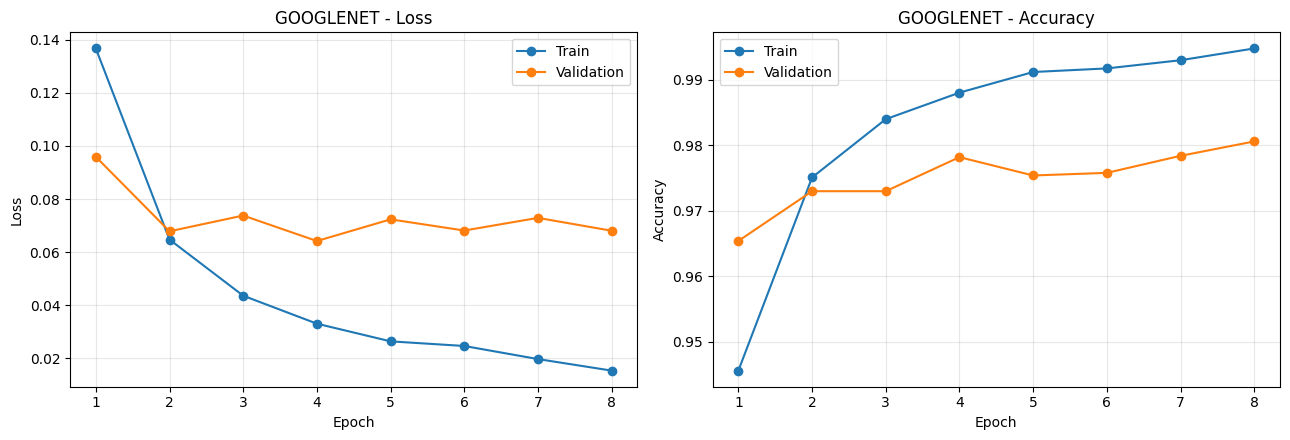

In [8]:
ep = range(1, EPOCHS + 1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(ep, history["train_loss"], "o-", label="Train")
ax[0].plot(ep, history["val_loss"],   "o-", label="Validation")
ax[0].set_title(f"{MODEL_NAME.upper()} - Loss"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Loss"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(ep, history["train_acc"], "o-", label="Train")
ax[1].plot(ep, history["val_acc"],   "o-", label="Validation")
ax[1].set_title(f"{MODEL_NAME.upper()} - Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

## 7. Evaluasi Test dan Confusion Matrix

Bobot terbaik berdasarkan validation accuracy dimuat sebelum mengevaluasi 5.000 gambar test. Confusion matrix menampilkan label aktual pada baris dan prediksi pada kolom, dengan urutan Female dan Male. Classification report memuat precision, recall, F1-score, dan support tiap kelas; test accuracy juga ditampilkan.


test:   0%|          | 0/79 [00:00<?, ?it/s]

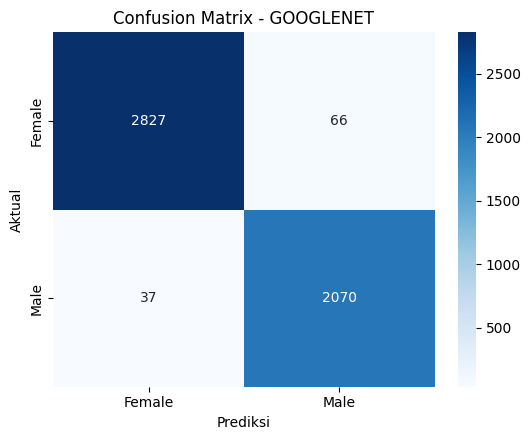

Classification Report:

              precision    recall  f1-score   support

      Female     0.9871    0.9772    0.9821      2893
        Male     0.9691    0.9824    0.9757      2107

    accuracy                         0.9794      5000
   macro avg     0.9781    0.9798    0.9789      5000
weighted avg     0.9795    0.9794    0.9794      5000

Test Accuracy: 0.9794


In [9]:
model.load_state_dict(torch.load(BEST_PATH, map_location=device))
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for x, y in tqdm(test_loader, desc="test"):
        x = x.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, enabled=(device.type == "cuda")):
            out = model(x)
        all_preds.extend(out.argmax(1).cpu().tolist())
        all_labels.extend(y.tolist())

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title(f"Confusion Matrix - {MODEL_NAME.upper()}"); plt.xlabel("Prediksi"); plt.ylabel("Aktual")
plt.tight_layout(); plt.show()

print("Classification Report:\n")
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))
test_acc = (np.array(all_preds) == np.array(all_labels)).mean()
print(f"Test Accuracy: {test_acc:.4f}")

## 8. Simpan dan Unduh Model

Kode menyimpan model saat ini sebagai `/content/alexnet_gender_final.pth`. File ini berisi nama arsitektur, state_dict, mapping kelas, ukuran input, dan test accuracy. Bobotnya berasal dari checkpoint terbaik yang telah dimuat pada tahap evaluasi, bukan otomatis bobot epoch terakhir.

**Penting:** `/content` adalah penyimpanan sementara Colab. Pesan “Model disimpan” belum berarti file telah diunduh atau dicadangkan ke Drive. Unduh `.pth` sebelum runtime berakhir; model yang sudah diunduh dapat diunggah kembali untuk inference tanpa training ulang.


In [10]:
FINAL_PATH = f"/content/{MODEL_NAME}_gender_final.pth"
torch.save({
    "model_name": MODEL_NAME,
    "state_dict": model.state_dict(),
    "class_to_idx": train_full.class_to_idx,
    "img_size": IMG_SIZE,
    "test_acc": float(test_acc),
}, FINAL_PATH)
print("Model disimpan di:", FINAL_PATH)

# (Opsional) unduh ke laptop. Hilangkan tanda # untuk menjalankan.
# from google.colab import files
# files.download(FINAL_PATH)

Model disimpan di: /content/googlenet_gender_final.pth


## 9. Inference: Prediksi Gambar dengan Model Terlatih

Cell berikut mengunggah gambar dan memakai objek `model` serta transform evaluasi yang masih ada di runtime. Gambar diubah menjadi RGB, diproses dengan transform yang sama, lalu model menghasilkan probabilitas Female/Male.

Pada runtime baru, objek `model` dan transform tersebut belum tersedia. Muat file `.pth` yang telah diunduh melalui setup inference terpisah terlebih dahulu. Tidak perlu download dataset, training, atau evaluasi seluruh test set untuk memprediksi satu gambar. Folder Drive khusus model bersifat opsional; folder bersama dapat memudahkan anggota kelompok memakai checkpoint yang sama.


Saving Raisya.jpeg to Raisya.jpeg


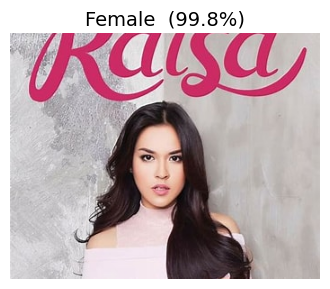

Raisya.jpeg -> Female: 99.8% | Male: 0.2%


In [11]:
from google.colab import files

model.eval()
uploaded = files.upload()

for fname, data in uploaded.items():
    img = Image.open(io.BytesIO(data)).convert("RGB")
    x = eval_tf(img).unsqueeze(0).to(device)
    with torch.no_grad():
        probs = torch.softmax(model(x), dim=1)[0].cpu()
    idx = int(probs.argmax())
    plt.figure(figsize=(4, 4.5))
    plt.imshow(img); plt.axis("off")
    plt.title(f"{class_names[idx]}  ({probs[idx]*100:.1f}%)", fontsize=14)
    plt.show()
    print(f"{fname} -> " + " | ".join(f"{c}: {p*100:.1f}%" for c, p in zip(class_names, probs)))